# Sumativa 1 - Parte 1: Preparación de datos y estadística descriptiva

**Dataset:** Framingham Heart Study (`data/framingham.csv`)

El Framingham Heart Study es un estudio cardiovascular longitudinal realizado en Massachusetts (EE. UU.). El dataset registra factores demográficos, conductuales y clínicos de 4.240 participantes y si desarrollaron enfermedad coronaria en los 10 años siguientes (`TenYearCHD`). El problema consiste en identificar qué factores se asocian a un mayor riesgo coronario, como apoyo a decisiones de prevención.

Contenido:
1. Carga y verificación de la estructura del dataset.
2. Reporte de calidad: faltantes, duplicados e inconsistencias.
3. Limpieza básica.
4. Estadística descriptiva de variables numéricas y categóricas.

## 0. Configuración

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

sns.set_theme(style="whitegrid", context="notebook")
pd.set_option("display.float_format", lambda x: f"{x:,.2f}")
np.random.seed(42)

FIG = Path("figuras")
FIG.mkdir(exist_ok=True)

COLORES = {
    "principal": "#4C72B0",
    "riesgo": "#C44E52",
    "mediana": "#55A868",
    "caja": "#8DA0CB",
}


def guardar_figura(nombre: str) -> None:
    """Ajusta el diseño, guarda la figura actual en la carpeta de figuras y la muestra."""
    plt.tight_layout()
    plt.savefig(FIG / f"{nombre}.png", dpi=200, bbox_inches="tight")
    plt.show()

## 1. Carga y estructura del dataset

In [2]:
df_raw = pd.read_csv("../data/framingham.csv")
print(f"Observaciones: {df_raw.shape[0]} | Variables: {df_raw.shape[1]}")
df_raw.head()

Observaciones: 4240 | Variables: 16


,male,age,education,currentSmoker,cigsPerDay,BPMeds,prevalentStroke,prevalentHyp,diabetes,totChol,sysBP,diaBP,BMI,heartRate,glucose,TenYearCHD
0,1,39,4.00,0,0.00,0.00,0,0,0,195.00,106.00,70.00,26.97,80.00,77.00,0
1,0,46,2.00,0,0.00,0.00,0,0,0,250.00,121.00,81.00,28.73,95.00,76.00,0
2,1,48,1.00,1,20.00,0.00,0,0,0,245.00,127.50,80.00,25.34,75.00,70.00,0
3,0,61,3.00,1,30.00,0.00,0,1,0,225.00,150.00,95.00,28.58,65.00,103.00,1
4,0,46,3.00,1,23.00,0.00,0,0,0,285.00,130.00,84.00,23.10,85.00,85.00,0


In [3]:
df_raw.info()

<class 'pandas.DataFrame'>
RangeIndex: 4240 entries, 0 to 4239
Data columns (total 16 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   male             4240 non-null   int64  
 1   age              4240 non-null   int64  
 2   education        4135 non-null   float64
 3   currentSmoker    4240 non-null   int64  
 4   cigsPerDay       4211 non-null   float64
 5   BPMeds           4187 non-null   float64
 6   prevalentStroke  4240 non-null   int64  
 7   prevalentHyp     4240 non-null   int64  
 8   diabetes         4240 non-null   int64  
 9   totChol          4190 non-null   float64
 10  sysBP            4240 non-null   float64
 11  diaBP            4240 non-null   float64
 12  BMI              4221 non-null   float64
 13  heartRate        4239 non-null   float64
 14  glucose          3852 non-null   float64
 15  TenYearCHD       4240 non-null   int64  
dtypes: float64(9), int64(7)
memory usage: 530.1 KB


### 1.1 Clasificación de las variables

Todas las variables vienen como números, pero varias son códigos de categorías (0/1 o niveles). Por eso se clasifican según su tipo estadístico, que define qué medidas y gráficos se usan en cada caso.

In [4]:
diccionario = pd.DataFrame([
    ("male",            "Sexo (1 = hombre, 0 = mujer)",               "Cualitativa", "Nominal (binaria)"),
    ("age",             "Edad (años)",                                "Cuantitativa", "Discreta"),
    ("education",       "Nivel educativo (1 a 4)",                    "Cualitativa", "Ordinal"),
    ("currentSmoker",   "Fumador actual (1 = sí)",                    "Cualitativa", "Nominal (binaria)"),
    ("cigsPerDay",      "Cigarrillos por día",                        "Cuantitativa", "Discreta"),
    ("BPMeds",          "Usa antihipertensivos (1 = sí)",             "Cualitativa", "Nominal (binaria)"),
    ("prevalentStroke", "Antecedente de ACV (1 = sí)",                "Cualitativa", "Nominal (binaria)"),
    ("prevalentHyp",    "Hipertensión diagnosticada (1 = sí)",        "Cualitativa", "Nominal (binaria)"),
    ("diabetes",        "Diabetes (1 = sí)",                          "Cualitativa", "Nominal (binaria)"),
    ("totChol",         "Colesterol total (mg/dL)",                   "Cuantitativa", "Continua"),
    ("sysBP",           "Presión arterial sistólica (mmHg)",          "Cuantitativa", "Continua"),
    ("diaBP",           "Presión arterial diastólica (mmHg)",         "Cuantitativa", "Continua"),
    ("BMI",             "Índice de masa corporal (kg/m²)",            "Cuantitativa", "Continua"),
    ("heartRate",       "Frecuencia cardíaca (lpm)",                  "Cuantitativa", "Discreta"),
    ("glucose",         "Glucosa (mg/dL)",                            "Cuantitativa", "Continua"),
    ("TenYearCHD",      "Enfermedad coronaria a 10 años (objetivo)",  "Cualitativa", "Nominal (binaria)"),
], columns=["variable", "descripcion", "tipo", "escala"])
diccionario

,variable,descripcion,tipo,escala
0,male,"Sexo (1 = hombre, 0 = mujer)",Cualitativa,Nominal (binaria)
1,age,Edad (años),Cuantitativa,Discreta
2,education,Nivel educativo (1 a 4),Cualitativa,Ordinal
3,currentSmoker,Fumador actual (1 = sí),Cualitativa,Nominal (binaria)
4,cigsPerDay,Cigarrillos por día,Cuantitativa,Discreta
5,BPMeds,Usa antihipertensivos (1 = sí),Cualitativa,Nominal (binaria)
6,prevalentStroke,Antecedente de ACV (1 = sí),Cualitativa,Nominal (binaria)
7,prevalentHyp,Hipertensión diagnosticada (1 = sí),Cualitativa,Nominal (binaria)
8,diabetes,Diabetes (1 = sí),Cualitativa,Nominal (binaria)
9,totChol,Colesterol total (mg/dL),Cuantitativa,Continua


In [5]:
NUM = diccionario.query("tipo == 'Cuantitativa'")["variable"].tolist()
CAT = diccionario.query("tipo == 'Cualitativa'")["variable"].tolist()
ORDINALES = diccionario.query("escala == 'Ordinal'")["variable"].tolist()
print("Numéricas:", NUM)
print("Categóricas:", CAT)

Numéricas: ['age', 'cigsPerDay', 'totChol', 'sysBP', 'diaBP', 'BMI', 'heartRate', 'glucose']
Categóricas: ['male', 'education', 'currentSmoker', 'BPMeds', 'prevalentStroke', 'prevalentHyp', 'diabetes', 'TenYearCHD']


## 2. Reporte de calidad de los datos

### 2.1 Valores faltantes

In [6]:
faltantes = pd.DataFrame({
    "n_faltantes": df_raw.isna().sum(),
    "porcentaje": df_raw.isna().mean() * 100,
}).query("n_faltantes > 0").sort_values("n_faltantes", ascending=False)

filas_incompletas = df_raw.isna().any(axis=1).sum()
print(f"Filas con al menos un faltante: {filas_incompletas} ({filas_incompletas / len(df_raw):.1%})")
faltantes

Filas con al menos un faltante: 582 (13.7%)


,n_faltantes,porcentaje
glucose,388,9.15
education,105,2.48
BPMeds,53,1.25
totChol,50,1.18
cigsPerDay,29,0.68
BMI,19,0.45
heartRate,1,0.02


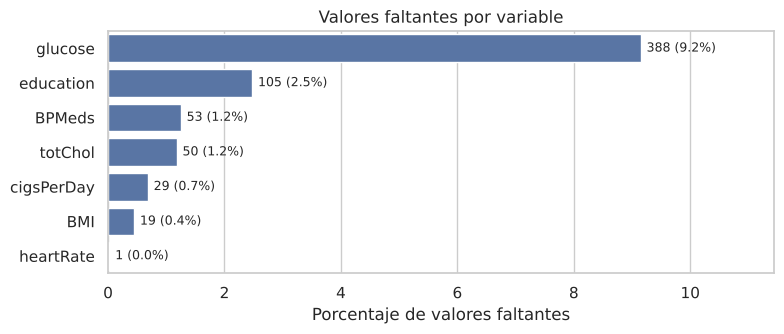

In [7]:
fig, ax = plt.subplots(figsize=(8, 3.5))
sns.barplot(x=faltantes["porcentaje"], y=faltantes.index, color=COLORES["principal"], ax=ax)
for i, (n, p) in enumerate(zip(faltantes["n_faltantes"], faltantes["porcentaje"])):
    ax.text(p + 0.1, i, f"{n} ({p:.1f}%)", va="center", fontsize=9)
ax.set(xlabel="Porcentaje de valores faltantes", ylabel="", title="Valores faltantes por variable")
ax.set_xlim(0, faltantes["porcentaje"].max() * 1.25)
guardar_figura("p1_fig1_faltantes")

Siete variables presentan valores faltantes. La más afectada es `glucose` (9,2 %), seguida de `education` (2,5 %); el resto no supera el 1,5 %. En total, 582 filas (13,7 %) tienen al menos un faltante, por lo que eliminarlas significaría perder una parte importante de la muestra.

### 2.2 Registros duplicados

In [8]:
duplicados = df_raw.duplicated().sum()
print(f"Filas duplicadas: {duplicados}")

Filas duplicadas: 0


No hay registros duplicados.

### 2.3 Inconsistencias y valores atípicos

Se revisan reglas de coherencia entre variables y se cuentan los valores atípicos con el criterio de Tukey (valores fuera de Q1 − 1,5·IQR y Q3 + 1,5·IQR).

In [9]:
reglas = {
    "No fumador con cigsPerDay > 0":              (df_raw["currentSmoker"] == 0) & (df_raw["cigsPerDay"] > 0),
    "Fumador con cigsPerDay = 0":                 (df_raw["currentSmoker"] == 1) & (df_raw["cigsPerDay"] == 0),
    "Fumador con cigsPerDay faltante":            (df_raw["currentSmoker"] == 1) & (df_raw["cigsPerDay"].isna()),
    "Presión diastólica ≥ sistólica":             df_raw["diaBP"] >= df_raw["sysBP"],
    "Usa antihipertensivos sin hipertensión":     (df_raw["BPMeds"] == 1) & (df_raw["prevalentHyp"] == 0),
    "Sin diagnóstico de diabetes y glucosa ≥ 126": (df_raw["diabetes"] == 0) & (df_raw["glucose"] >= 126),
}
pd.Series({k: int(v.sum()) for k, v in reglas.items()}, name="casos").to_frame()

,casos
No fumador con cigsPerDay > 0,0
Fumador con cigsPerDay = 0,0
Fumador con cigsPerDay faltante,29
Presión diastólica ≥ sistólica,0
Usa antihipertensivos sin hipertensión,0
Sin diagnóstico de diabetes y glucosa ≥ 126,22


In [10]:
def atipicos_tukey(s: pd.Series) -> int:
    """Cuenta los valores fuera del rango [Q1 - 1,5·IQR, Q3 + 1,5·IQR] (criterio de Tukey)."""
    q1, q3 = s.quantile([0.25, 0.75])
    iqr = q3 - q1
    return int(((s < q1 - 1.5 * iqr) | (s > q3 + 1.5 * iqr)).sum())

pd.DataFrame({
    "n_atipicos": {c: atipicos_tukey(df_raw[c]) for c in NUM},
    "minimo": df_raw[NUM].min(),
    "maximo": df_raw[NUM].max(),
})

,n_atipicos,minimo,maximo
age,0,32.00,70.00
cigsPerDay,12,0.00,70.00
totChol,56,107.00,696.00
sysBP,126,83.50,295.00
diaBP,77,48.00,142.50
BMI,97,15.54,56.80
heartRate,76,44.00,143.00
glucose,188,40.00,394.00


Hallazgos:
- No hay contradicciones lógicas entre `currentSmoker` y `cigsPerDay`, ni entre presión sistólica y diastólica.
- Los 29 faltantes de `cigsPerDay` corresponden todos a fumadores, es decir, se sabe que fuman pero no cuánto.
- 22 participantes sin diagnóstico de diabetes presentan glucosa ≥ 126 mg/dL. No se tratan como errores, porque pueden ser casos de diabetes no diagnosticada o una medición aislada.
- Hay valores atípicos en todas las variables clínicas (por ejemplo, colesterol de 696 mg/dL, glucosa de 394 mg/dL o presión sistólica de 295 mmHg). Son valores extremos, pero posibles en pacientes con enfermedades severas, por lo que se conservan. Por esto se reportan también la mediana y el IQR, que no se ven afectados por ellos.

## 3. Limpieza básica

Decisiones:

1. `cigsPerDay` en fumadores: los 29 faltantes se imputan con la mediana de cigarrillos de los fumadores (20). Usar la mediana global (0) sería incorrecto, porque se sabe que estas personas fuman.
2. Resto de los faltantes: se mantienen. Cada análisis usa los casos disponibles en las variables que utiliza. Eliminar las filas incompletas descartaría el 13,7 % de la muestra, y la imputación se trabajará en una fase posterior del proyecto.
3. Valores atípicos: se conservan por ser clínicamente posibles.
4. Tipos de datos: las variables binarias y `education` se convierten a enteros con soporte de faltantes (`Int64`), y se crean etiquetas legibles para tablas y gráficos.

In [11]:
df = df_raw.copy()

mediana_fumadores = df.loc[df["currentSmoker"] == 1, "cigsPerDay"].median()
mask = (df["currentSmoker"] == 1) & (df["cigsPerDay"].isna())
df.loc[mask, "cigsPerDay"] = mediana_fumadores
print(f"cigsPerDay imputados: {mask.sum()} (mediana de fumadores = {mediana_fumadores:.0f})")

for c in CAT:
    df[c] = df[c].astype("Int64")

df.to_csv("../data/framingham_limpio.csv", index=False)
print(f"Dataset limpio: {df.shape[0]} filas | faltantes restantes: {df.isna().sum().sum()}")

cigsPerDay imputados: 29 (mediana de fumadores = 20)
Dataset limpio: 4240 filas | faltantes restantes: 616


In [12]:
ETIQUETAS = {
    "male": {0: "Mujer", 1: "Hombre"},
    "education": {1: "Secundaria incompleta", 2: "Secundaria completa",
                  3: "Técnica / univ. incompleta", 4: "Universitaria"},
    "currentSmoker": {0: "No", 1: "Sí"},
    "BPMeds": {0: "No", 1: "Sí"},
    "prevalentStroke": {0: "No", 1: "Sí"},
    "prevalentHyp": {0: "No", 1: "Sí"},
    "diabetes": {0: "No", 1: "Sí"},
    "TenYearCHD": {0: "No", 1: "Sí"},
}
NOMBRES = dict(zip(diccionario["variable"], diccionario["descripcion"]))

## 4. Estadística descriptiva: variables numéricas

### 4.1 Medidas de tendencia central, dispersión y forma

In [13]:
def resumen_numerico(s: pd.Series) -> pd.Series:
    """Calcula medidas de tendencia central, dispersión y forma de una variable numérica."""
    q1, q3 = s.quantile([0.25, 0.75])
    return pd.Series({
        "n": s.count(),
        "media": s.mean(),
        "mediana": s.median(),
        "moda": s.mode().iloc[0],
        "desv_est": s.std(),
        "CV_%": s.std() / s.mean() * 100,
        "min": s.min(),
        "Q1": q1,
        "Q3": q3,
        "max": s.max(),
        "IQR": q3 - q1,
        "asimetria": s.skew(),
        "curtosis": s.kurt(),
    })

tabla_num = df[NUM].apply(resumen_numerico).T
tabla_num["n"] = tabla_num["n"].astype(int)
tabla_num

,n,media,mediana,moda,desv_est,CV_%,min,Q1,Q3,max,IQR,asimetria,curtosis
age,4240,49.58,49.00,40.00,8.57,17.29,32.00,42.00,56.00,70.00,14.00,0.23,-0.99
cigsPerDay,4240,9.08,0.00,0.00,11.92,131.22,0.00,0.00,20.00,70.00,20.00,1.23,0.97
totChol,4190,236.70,234.00,240.00,44.59,18.84,107.00,206.00,263.00,696.00,57.00,0.87,4.13
sysBP,4240,132.35,128.00,120.00,22.03,16.65,83.50,117.00,144.00,295.00,27.00,1.15,2.16
diaBP,4240,82.90,82.00,80.00,11.91,14.37,48.00,75.00,90.00,142.50,15.00,0.71,1.28
BMI,4221,25.80,25.40,22.19,4.08,15.81,15.54,23.07,28.04,56.80,4.97,0.98,2.66
heartRate,4239,75.88,75.00,75.00,12.03,15.85,44.00,68.00,83.00,143.00,15.00,0.64,0.91
glucose,3852,81.96,78.00,75.00,23.95,29.23,40.00,71.00,87.00,394.00,16.00,6.21,58.70


Interpretación:
- Edad: los participantes tienen entre 32 y 70 años, con media de 49,6 y mediana de 49. Media y mediana casi coinciden y la asimetría es cercana a 0, así que la distribución es aproximadamente simétrica y algo aplanada (curtosis negativa).
- Presión sistólica (`sysBP`), colesterol (`totChol`) e IMC (`BMI`): tienen asimetría positiva (media mayor que la mediana), con una cola de pacientes con valores altos. Su variabilidad relativa es moderada (CV entre 15 % y 19 %). La mediana del IMC (25,4) ya está en el rango de sobrepeso, y la mediana del colesterol (234 mg/dL) está cerca del límite alto recomendado (240 mg/dL).
- Glucosa: es la variable más asimétrica (asimetría de 6,2) y con colas más pesadas (curtosis de 58,7). La mayoría de los valores está cerca de 78 mg/dL, pero hay algunos casos muy altos, propios de pacientes diabéticos. En esta variable la mediana y el IQR representan mejor el valor típico que la media y la desviación estándar.
- Cigarrillos por día: la mediana es 0 porque cerca de la mitad no fuma, y el CV supera el 130 %. Como tiene muchos ceros, se describe también solo para los fumadores (mediana de 20 cigarrillos, un paquete diario).

### 4.2 Distribuciones

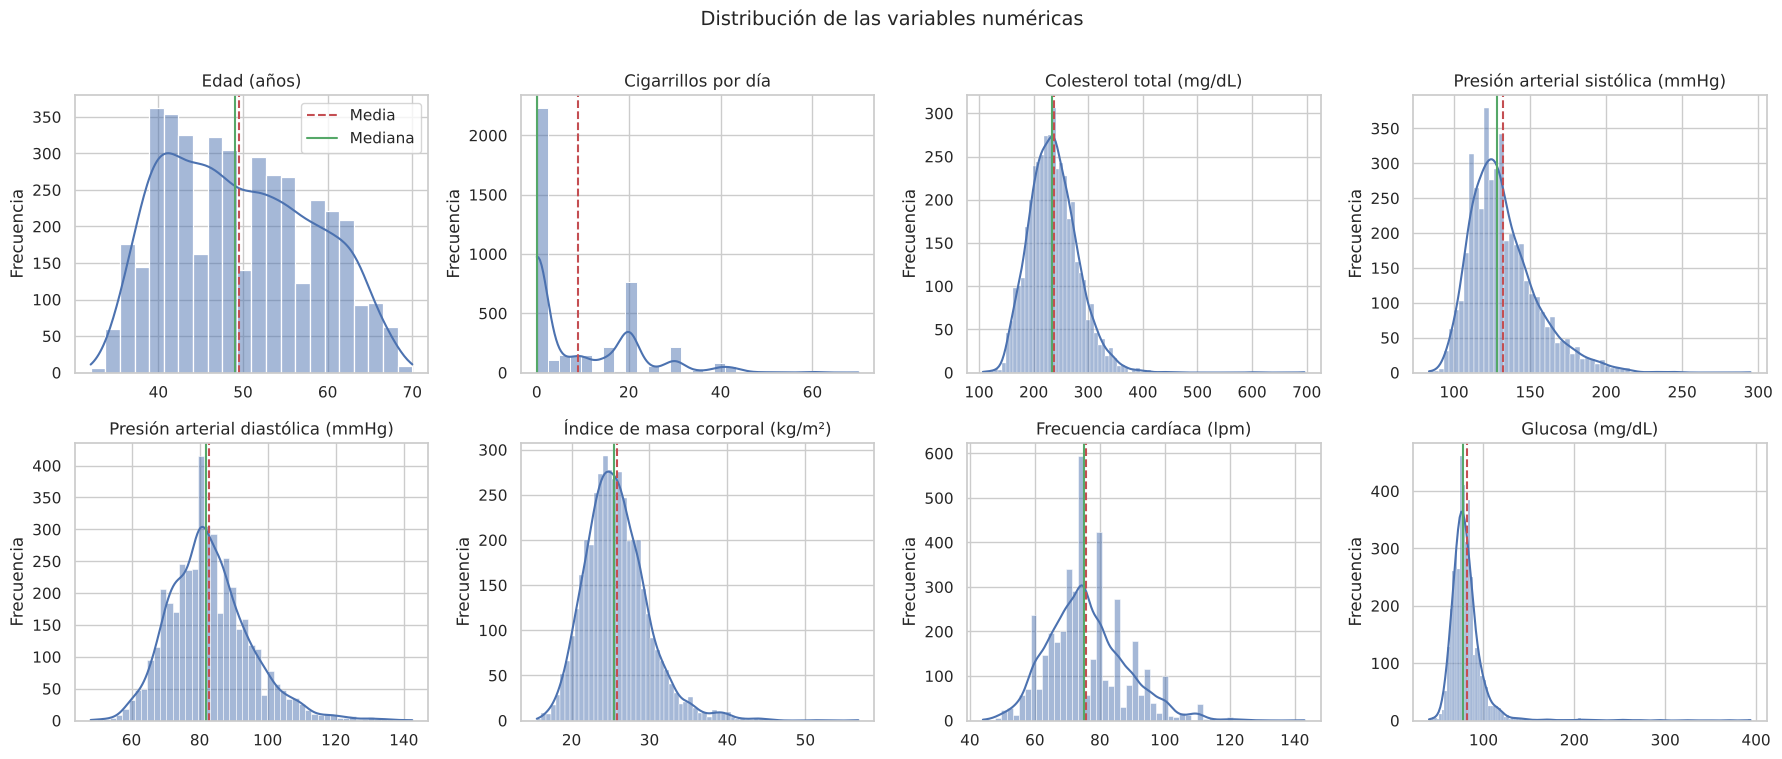

In [14]:
fig, axes = plt.subplots(2, 4, figsize=(18, 7.5))
for ax, c in zip(axes.ravel(), NUM):
    sns.histplot(df[c].dropna(), kde=True, ax=ax, color=COLORES["principal"], edgecolor="white")
    ax.axvline(df[c].mean(), color=COLORES["riesgo"], ls="--", lw=1.5, label="Media")
    ax.axvline(df[c].median(), color=COLORES["mediana"], ls="-", lw=1.5, label="Mediana")
    ax.set(title=NOMBRES[c], xlabel="", ylabel="Frecuencia")
axes[0, 0].legend()
plt.suptitle("Distribución de las variables numéricas", fontsize=14, y=1.01)
guardar_figura("p1_fig2_histogramas")

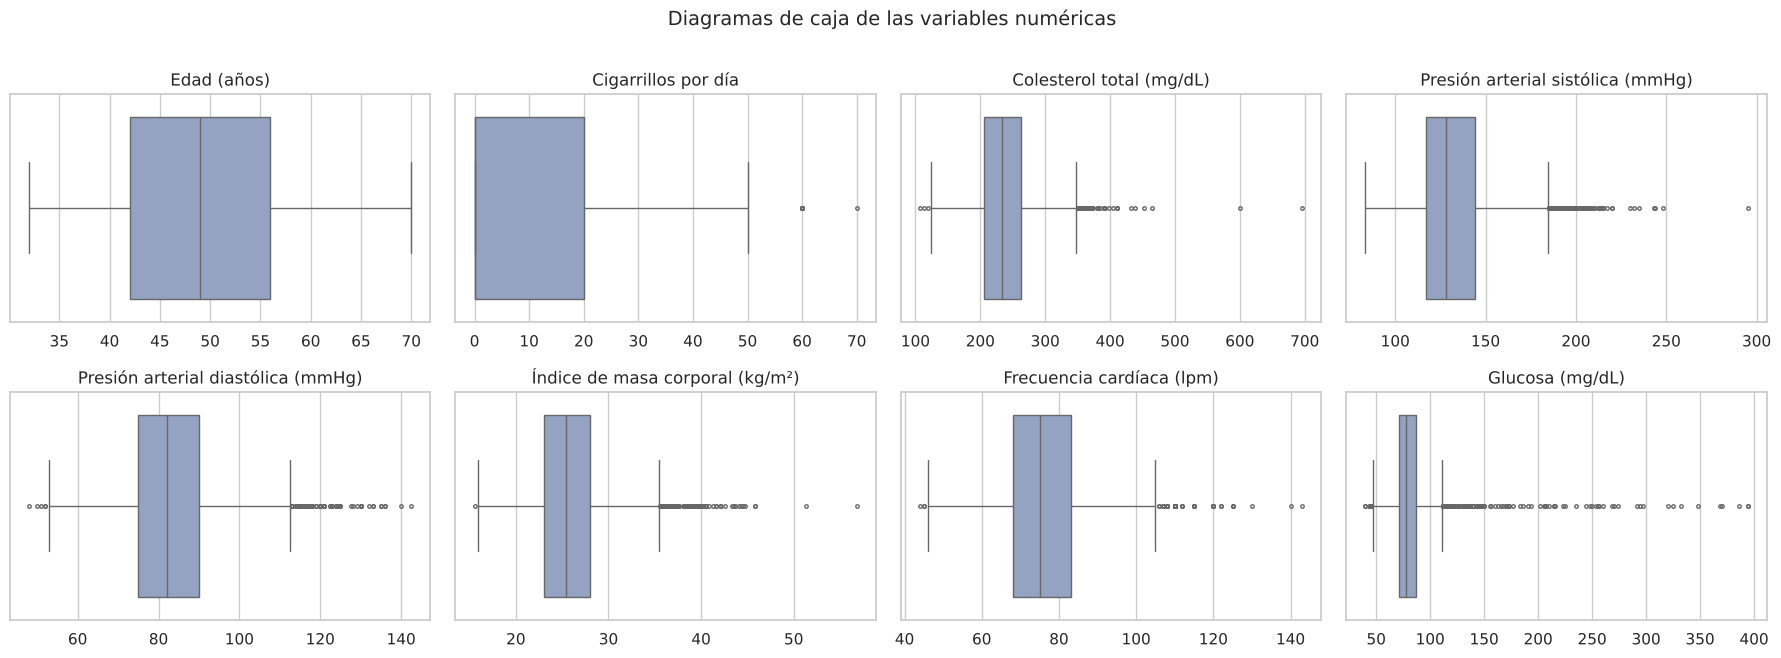

In [15]:
fig, axes = plt.subplots(2, 4, figsize=(18, 6.5))
for ax, c in zip(axes.ravel(), NUM):
    sns.boxplot(x=df[c], ax=ax, color=COLORES["caja"], fliersize=2.5)
    ax.set(title=NOMBRES[c], xlabel="")
plt.suptitle("Diagramas de caja de las variables numéricas", fontsize=14, y=1.01)
guardar_figura("p1_fig3_boxplots")

Los histogramas coinciden con la tabla: la edad es aproximadamente simétrica, mientras que la presión, el colesterol, el IMC y en especial la glucosa tienen cola hacia la derecha (la media queda a la derecha de la mediana). En los diagramas de caja los atípicos están en el extremo superior, que corresponde a pacientes con valores clínicos de mayor riesgo.

In [16]:
fumadores = df.loc[df["currentSmoker"] == 1, "cigsPerDay"]
print("Cigarrillos por día (solo fumadores):")
resumen_numerico(fumadores).round(2).to_frame("solo fumadores").T.astype({"n": int})

Cigarrillos por día (solo fumadores):


,n,media,mediana,moda,desv_est,CV_%,min,Q1,Q3,max,IQR,asimetria,curtosis
solo fumadores,2095,18.38,20.00,20.00,10.79,58.72,1.00,10.00,20.00,70.00,10.00,0.73,0.93


### 4.3 Indicadores de riesgo clínico

Porcentaje de participantes que superan umbrales clínicos de uso habitual.

In [17]:
def porcentaje_sobre_umbral(s: pd.Series, umbral: float) -> float:
    """Porcentaje de valores observados (sin faltantes) mayores o iguales al umbral."""
    s = s.dropna()
    return (s >= umbral).mean() * 100


UMBRALES = [
    ("Presión sistólica ≥ 140 mmHg", "sysBP", 140),
    ("Colesterol total ≥ 240 mg/dL", "totChol", 240),
    ("IMC ≥ 25 (sobrepeso u obesidad)", "BMI", 25),
    ("IMC ≥ 30 (obesidad)", "BMI", 30),
    ("Glucosa ≥ 126 mg/dL", "glucose", 126),
]
pd.Series(
    {etiqueta: porcentaje_sobre_umbral(df[col], u) for etiqueta, col, u in UMBRALES},
    name="% de participantes",
).round(1).to_frame()

,% de participantes
Presión sistólica ≥ 140 mmHg,30.30
Colesterol total ≥ 240 mg/dL,44.90
IMC ≥ 25 (sobrepeso u obesidad),54.30
IMC ≥ 30 (obesidad),12.80
Glucosa ≥ 126 mg/dL,2.20


El 30,3 % de los participantes tiene presión sistólica elevada, el 44,9 % tiene colesterol alto y el 54,3 % tiene sobrepeso u obesidad. Es una población con varios factores de riesgo cardiovascular presentes.

## 5. Estadística descriptiva: variables categóricas

### 5.1 Frecuencias absolutas y relativas

In [18]:
def tabla_frecuencias(datos: pd.DataFrame, c: str) -> pd.DataFrame:
    """Frecuencias absolutas y relativas de una variable categórica (acumuladas si es ordinal)."""
    s = datos[c].map(ETIQUETAS[c]).fillna("Sin dato")
    t = s.value_counts().to_frame("frec_absoluta")
    t["frec_relativa_%"] = t["frec_absoluta"] / len(s) * 100
    if c in ORDINALES:
        orden = list(ETIQUETAS[c].values()) + (["Sin dato"] if "Sin dato" in t.index else [])
        t = t.loc[orden]
        t["frec_acumulada_%"] = t["frec_relativa_%"].cumsum()
    t.index.name = c
    return t

for c in CAT:
    print(f"\n{NOMBRES[c]}")
    display(tabla_frecuencias(df, c))


Sexo (1 = hombre, 0 = mujer)


,frec_absoluta,frec_relativa_%
male,,
Mujer,2420,57.08
Hombre,1820,42.92



Nivel educativo (1 a 4)


,frec_absoluta,frec_relativa_%,frec_acumulada_%
education,,,
Secundaria incompleta,1720,40.57,40.57
Secundaria completa,1253,29.55,70.12
Técnica / univ. incompleta,689,16.25,86.37
Universitaria,473,11.16,97.52
Sin dato,105,2.48,100.00



Fumador actual (1 = sí)


...

,frec_absoluta,frec_relativa_%
prevalentHyp,,
No,2923,68.94
Sí,1317,31.06



Diabetes (1 = sí)


,frec_absoluta,frec_relativa_%
diabetes,,
No,4131,97.43
Sí,109,2.57



Enfermedad coronaria a 10 años (objetivo)


,frec_absoluta,frec_relativa_%
TenYearCHD,,
No,3596,84.81
Sí,644,15.19


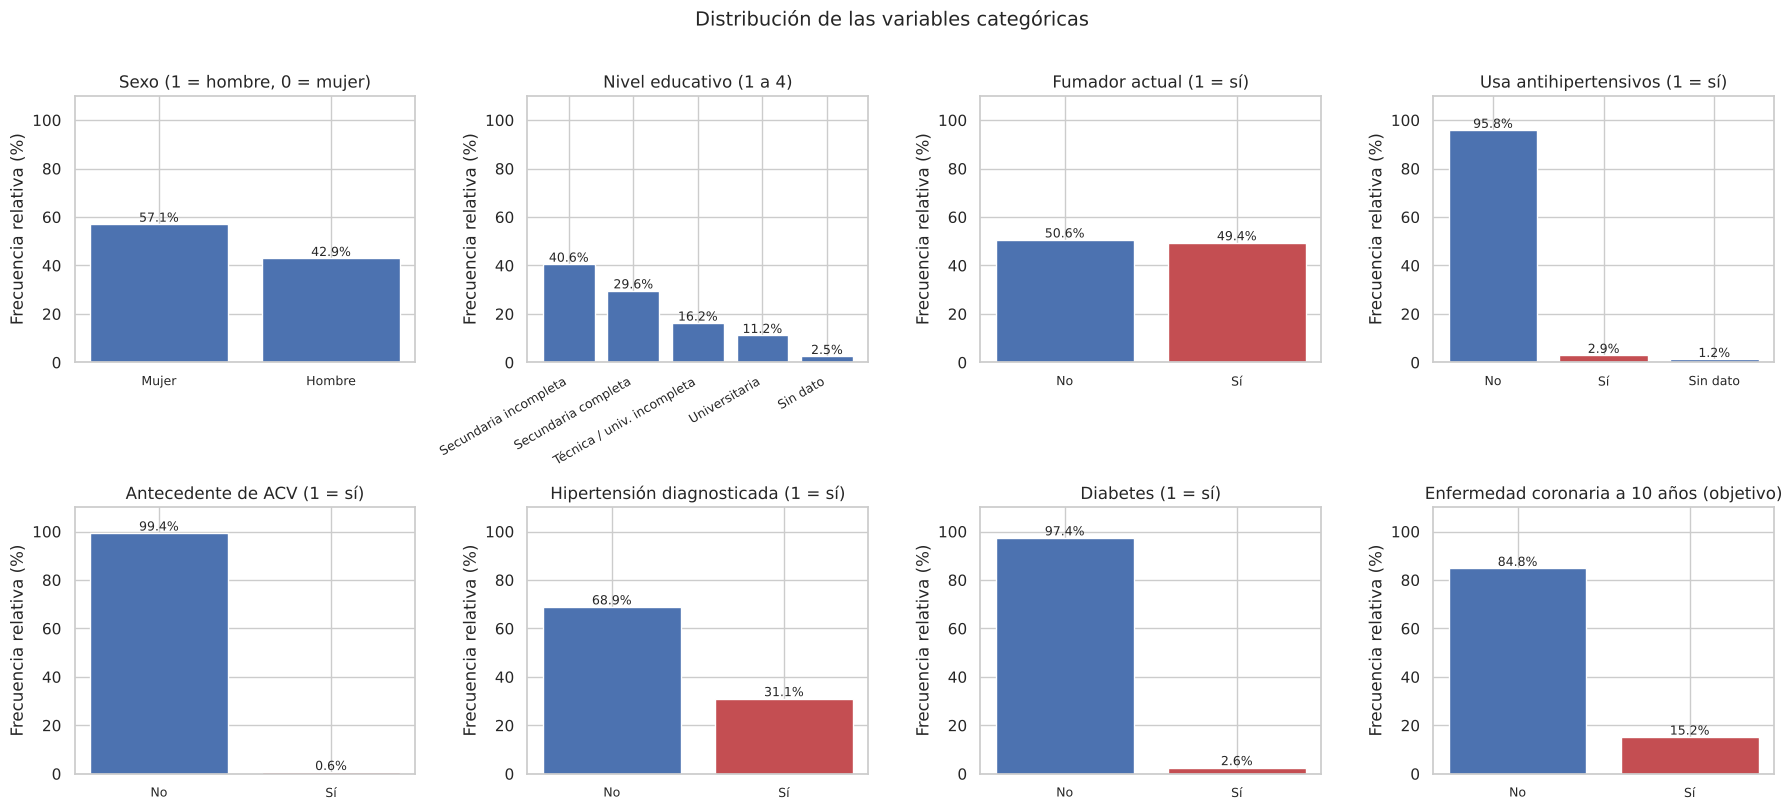

In [19]:
fig, axes = plt.subplots(2, 4, figsize=(18, 8))
for ax, c in zip(axes.ravel(), CAT):
    t = tabla_frecuencias(df, c)
    colores = [COLORES["riesgo"] if i == "Sí" else COLORES["principal"] for i in t.index]
    ax.bar(range(len(t)), t["frec_relativa_%"], color=colores)
    ordinal = c in ORDINALES
    ax.set_xticks(range(len(t)), t.index, rotation=30 if ordinal else 0,
                  ha="right" if ordinal else "center", fontsize=9)
    for i, v in enumerate(t["frec_relativa_%"]):
        ax.text(i, v + 1, f"{v:.1f}%", ha="center", fontsize=9)
    ax.set(title=NOMBRES[c], ylabel="Frecuencia relativa (%)", ylim=(0, 110))
plt.suptitle("Distribución de las variables categóricas", fontsize=14, y=1.01)
guardar_figura("p1_fig4_categoricas")

Interpretación:
- Variable objetivo (`TenYearCHD`): el 15,2 % de los participantes desarrolló enfermedad coronaria en 10 años (644 de 4.240). Las clases están desbalanceadas, algo a considerar en las fases de modelamiento predictivo.
- Sexo: predominan las mujeres (57,1 %).
- Tabaquismo: casi la mitad de la muestra fuma (49,4 %), una proporción alta propia de la época del estudio.
- Hipertensión: el 31,1 % tiene hipertensión diagnosticada, pero solo el 2,9 % de la muestra usa antihipertensivos (cerca del 9 % de los hipertensos), lo que indica que la mayoría de los hipertensos no está en tratamiento.
- Diabetes (2,6 %) y antecedente de ACV (0,6 %): son poco frecuentes, por lo que los análisis que las usen tendrán más incertidumbre.
- Educación: el nivel más frecuente es secundaria incompleta (40,6 %), y la frecuencia disminuye a medida que aumenta el nivel educativo.

## 6. Síntesis

- El dataset tiene 4.240 registros y 16 variables, sin duplicados ni inconsistencias lógicas. Hay faltantes en 7 variables, principalmente en `glucose` (9,2 %).
- En la limpieza se imputaron los cigarrillos faltantes de los fumadores con su mediana y se conservaron los valores atípicos. El resto de los faltantes se maneja con los casos disponibles en cada análisis.
- Las variables clínicas tienen asimetría positiva, por lo que la mediana y el IQR son más representativos que la media, sobre todo en la glucosa.
- La población tiene una alta prevalencia de factores de riesgo (tabaquismo, hipertensión, colesterol alto y sobrepeso) y una tasa de enfermedad coronaria del 15,2 %. Las siguientes secciones analizan qué factores se asocian a la enfermedad.